# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'nraja3'   # <-- set this
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

269 epochs over 961 days; median quoted error 0.040 mag; rms of the light curve 0.260 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


Strongest period: 961.010 d; peak power: 0.293005; white-noise FAP: 3.6257e-18
Top local peaks (period d, power): [(np.float64(534.65), np.float64(0.2729)), (np.float64(300.97), np.float64(0.2527)), (np.float64(172.06), np.float64(0.1876)), (np.float64(43.42), np.float64(0.0906)), (np.float64(56.04), np.float64(0.0603)), (np.float64(104.75), np.float64(0.0562)), (np.float64(39.18), np.float64(0.0535)), (np.float64(123.55), np.float64(0.0442))]


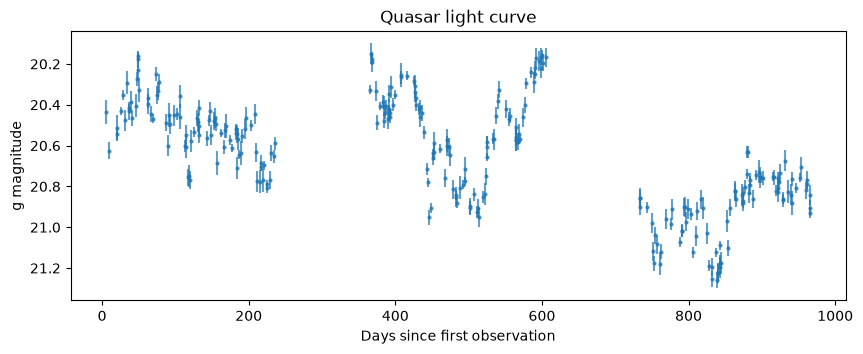

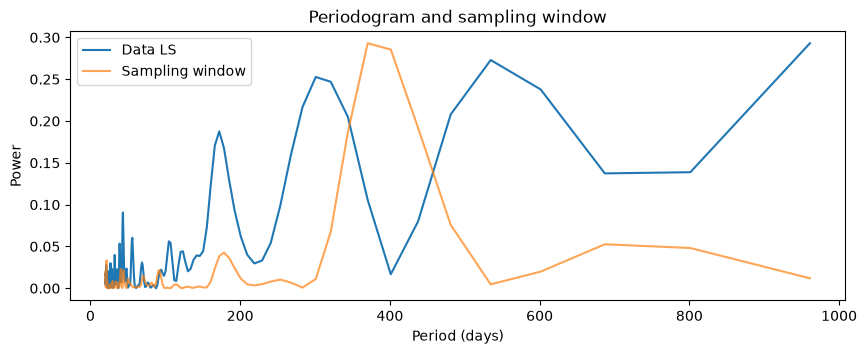

In [2]:
# Part 1: your work here
freq = np.linspace(1/T, 1/20, int(np.ceil((1/20 - 1/T)*5*T))+1)
ls = LombScargle(t, y, dy=e)
power = ls.power(freq)
window = LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False).power(freq)
window = window * power.max()/window.max()
i_peak = int(np.argmax(power))
period_peak = 1/freq[i_peak]
fap_white = ls.false_alarm_probability(power[i_peak], method='baluev', minimum_frequency=freq[0], maximum_frequency=freq[-1])
print(f"Strongest period: {period_peak:.3f} d; peak power: {power[i_peak]:.6f}; white-noise FAP: {fap_white:.5g}")
# Local peaks for possible aliases
from scipy.signal import find_peaks
peaks, _ = find_peaks(power)
peaks = sorted(peaks, key=lambda j: power[j], reverse=True)[:8]
print("Top local peaks (period d, power):", [(round(1/freq[j],2), round(power[j],4)) for j in peaks])
fig, ax = plt.subplots(figsize=(10,3.5))
ax.errorbar(t,y,yerr=e,fmt='.',ms=4,alpha=.7)
ax.invert_yaxis(); ax.set(xlabel='Days since first observation',ylabel='g magnitude',title='Quasar light curve'); plt.show()
fig, ax = plt.subplots(figsize=(10,3.5))
ax.plot(1/freq,power,label='Data LS'); ax.plot(1/freq,window, label='Sampling window',alpha=.7)
ax.set(xlabel='Period (days)',ylabel='Power',title='Periodogram and sampling window'); ax.legend(); plt.show()

**ANSWER (a few sentences):**

*The highest peak was at 961.01 days with a false-alarm probability of 3.63 × 10⁻¹⁸. Other peaks were at 534.65, 300.97, and 172.06 days, which might be from the sampling gaps. The window had a peak around 370 days. We don't have enough data to look past 961 days. Astropy assumes white noise, but quasars have correlated noise, so the probability might not be right.*

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ ___ (+___ / −___) mag, $\tau = $ ___ (+___ / −___) d, $T/\tau = $ ___; the exponential kernel beats the squared exponential by $\Delta\ln L = $ ___; ___ of ___ held-out points are inside the 68% band.


In [3]:
# Part 2: your work here
dt = np.abs(t[:,None]-t[None,:])
mu_center = float(np.median(y))

def cov(dt, e, s, tau, kind='exp'):
    corr = np.exp(-dt/tau) if kind == 'exp' else np.exp(-.5*(dt/tau)**2)
    return s*s*corr + np.diag(e*e)

def lnlike(theta, tt=t, yy=y, ee=e, kind='exp'):
    mu, s, tau = theta
    if not (np.isfinite(mu) and s>0 and tau>0): return -np.inf
    K = cov(np.abs(tt[:,None]-tt[None,:]),ee,s,tau,kind)
    try:
        c, low = cho_factor(K, lower=True, check_finite=False)
        z = yy-mu
        return -.5*(z @ cho_solve((c,low),z,check_finite=False) + 2*np.log(np.diag(c)).sum() + len(yy)*np.log(2*np.pi))
    except np.linalg.LinAlgError:
        return -np.inf

def logprior(theta):
    mu,s,tau=theta
    return 0. if (mu_center-2 < mu < mu_center+2 and 0<s<1 and 10<tau<4000) else -np.inf

def logpost(theta):
    lp=logprior(theta)
    return lp+lnlike(theta) if np.isfinite(lp) else -np.inf

bounds=[(mu_center-1.999,mu_center+1.999),(.0001,.9999),(10.001,3999.999)]
def fit_gp(tt,yy,ee,kind='exp', starts=None):
    if starts is None:
        med=float(np.median(yy)); sd=max(float(np.std(yy)),.01)
        starts=[(med,min(sd,.95),q) for q in (30,150,500,1500)]
    results=[minimize(lambda th:-lnlike(th,tt,yy,ee,kind),x0=x,method='L-BFGS-B',bounds=bounds,options={'maxiter':300}) for x in starts]
    good=[r for r in results if np.isfinite(r.fun)]
    return min(good,key=lambda r:r.fun),results
fit_exp, starts_exp = fit_gp(t,y,e,'exp')
fit_sq, starts_sq = fit_gp(t,y,e,'sq')
th_exp, th_sq = fit_exp.x, fit_sq.x
ll_exp, ll_sq = -fit_exp.fun, -fit_sq.fun
print('DRW starts (log likelihood):',[(round(-r.fun,3),r.success) for r in starts_exp])
print('EXP fit mu,s,tau:',th_exp,'log L:',ll_exp)
print('SQ  fit mu,s,tau:',th_sq,'log L:',ll_sq)
print('lnL(exp)-lnL(sq):',ll_exp-ll_sq)

DRW starts (log likelihood): [(np.float64(287.513), True), (np.float64(287.513), True), (np.float64(284.024), True), (np.float64(285.477), True)]
EXP fit mu,s,tau: [20.62115649  0.25532553 60.1587673 ] log L: 287.5129419020469
SQ  fit mu,s,tau: [20.64048549  0.34214093 10.001     ] log L: 192.75192348294823
lnL(exp)-lnL(sq): 94.76101841909869


100%|██████████| 1200/1200 [00:35<00:00, 33.50it/s]


Autocorrelation times: [41.33335565 93.02796824 90.86200007] post-burn steps / max tau: 8.59956435783776
mu: 20.6091 (+0.4253/-0.4234) mag
s: 0.6767 (+0.2366/-0.2766) mag
tau: 441.5914 (+384.9821/-285.2316) days
68% tau interval: 156.35980924122254 826.5734849178505  days


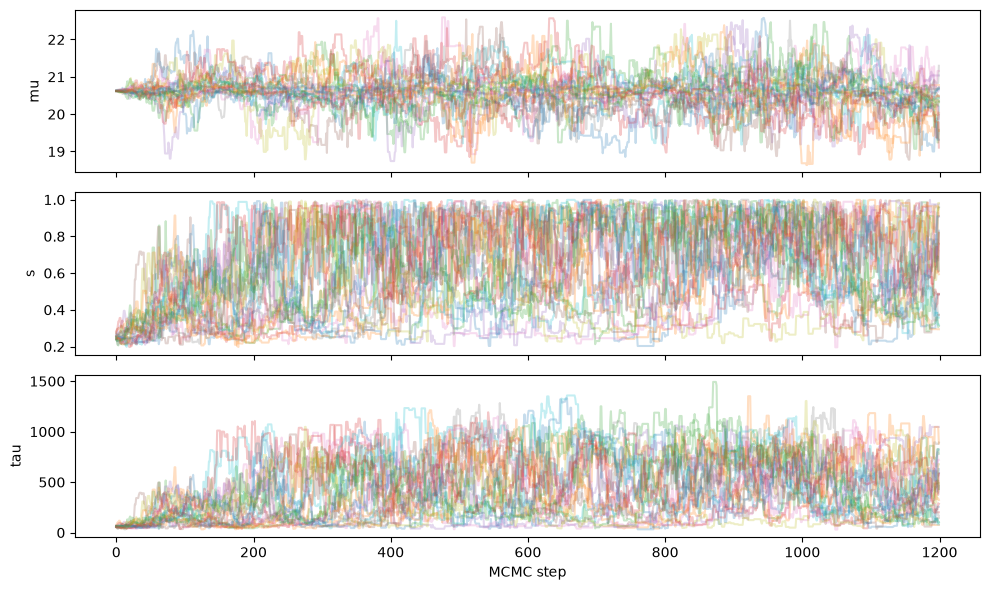

In [5]:
rng = np.random.default_rng(42)
walkers=24
start=th_exp + rng.normal(size=(walkers,3))*np.array([.005,max(.008,th_exp[1]*.04),max(5,th_exp[2]*.04)])
start[:,0]=np.clip(start[:,0],mu_center-1.9,mu_center+1.9)
start[:,1]=np.clip(start[:,1],.001,.99)
start[:,2]=np.clip(start[:,2],10.1,3999)
sampler=emcee.EnsembleSampler(walkers,3,logpost)
sampler.run_mcmc(start,1200,progress=True)
try:
    act=sampler.get_autocorr_time(tol=0)
    print('Autocorrelation times:',act,'post-burn steps / max tau:',(1200-400)/max(act))
except Exception as exc: print('Autocorrelation diagnostic unavailable:',str(exc))
chain=sampler.get_chain(discard=400,thin=5,flat=True)
q=np.percentile(chain,[16,50,84],axis=0)
for name,j,unit in [('mu',0,'mag'),('s',1,'mag'),('tau',2,'days')]:
    print(f'{name}: {q[1,j]:.4f} (+{q[2,j]-q[1,j]:.4f}/-{q[1,j]-q[0,j]:.4f}) {unit}')
print('68% tau interval:',q[0,2],q[2,2],' days')
fig,ax=plt.subplots(3,1,figsize=(10,6),sharex=True)
for j,label in enumerate(['mu','s','tau']): ax[j].plot(sampler.get_chain()[:,:,j],alpha=.25);ax[j].set_ylabel(label)
ax[-1].set_xlabel('MCMC step');plt.tight_layout();plt.show()

Block starts: [392.13, 183.72, 874.42, 540.27] held out N: 47
exp: N=47, inside 68%=0.766, R2 vs training-mean=0.729, mean predicted noise=0.1200


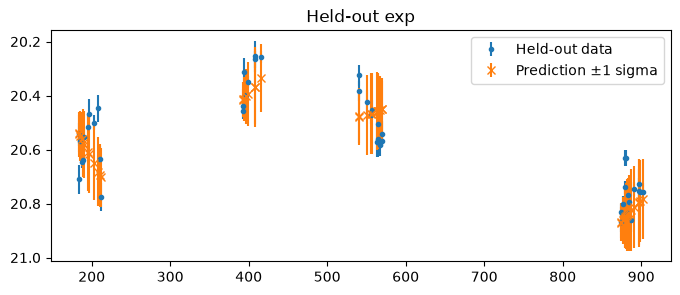

sq: N=47, inside 68%=0.766, R2 vs training-mean=0.541, mean predicted noise=0.1846


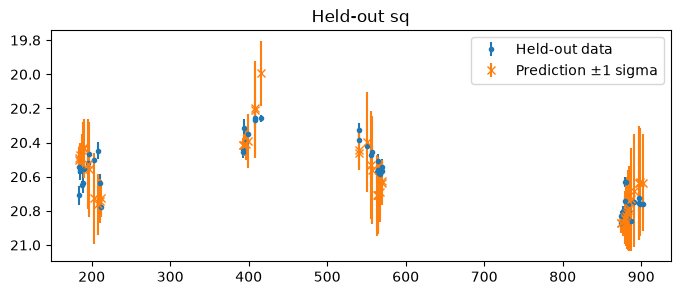

In [11]:
def gp_predict(ttr, ytr, etr, tte, theta, kind='exp', new_err=None):
    mu, s, tau = theta

    dtr = np.abs(ttr[:, None] - ttr[None, :])
    dte = np.abs(tte[:, None] - ttr[None, :])

    if kind == 'exp':
        K = s**2 * np.exp(-dtr/tau)
        Ks = s**2 * np.exp(-dte/tau)
    else:
        K = s**2 * np.exp(-0.5*(dtr/tau)**2)
        Ks = s**2 * np.exp(-0.5*(dte/tau)**2)

    K += np.diag(etr**2)

    c = cho_factor(K, lower=True)
    m = mu + Ks @ cho_solve(c, ytr-mu)

    var = s**2 - np.sum(Ks * cho_solve(c, Ks.T).T, axis=1)

    if new_err is not None:
        var += np.asarray(new_err)**2

    return m, np.sqrt(np.maximum(var, 0))

gaps=np.where(np.diff(t)>45)[0]
seasons=np.split(np.arange(len(t)),gaps+1)
candidates=[]
for ids in seasons:
    times=t[ids]
    for start_day in times:
        if start_day+30 <= times.max():
            held=ids[(times>=start_day)&(times<start_day+30)]
            if len(held)>0: candidates.append((float(start_day),held))
rr=np.random.default_rng(1234)
blocks=None
for attempt in range(10000):
    choice=rr.permutation(len(candidates)); selected=[]
    for k in choice:
        st,idx=candidates[k]
        if all(abs(st-other_st)>=90 for other_st,_ in selected):
            selected.append((st,idx))
        if len(selected)==4: break
    if len(selected)==4:
        blocks=selected;break
if blocks is None: raise RuntimeError('Cannot choose 4 blocks with >=60 day separation; inspect season boundaries.')
held=np.unique(np.concatenate([idx for _,idx in blocks])); train=np.setdiff1d(np.arange(len(t)),held)
print('Block starts:',[round(st,2) for st,_ in blocks], 'held out N:',len(held))
for kind in ['exp','sq']:
    f,_=fit_gp(t[train],y[train],e[train],kind)
    ym,sd=gp_predict(t[train],y[train],e[train],t[held],f.x,kind,new_err=e[held])
    inside=np.mean(np.abs(y[held]-ym)<=sd)
    mse=np.mean((y[held]-ym)**2)
    baseline=np.mean((y[held]-np.mean(y[train]))**2)
    r2=1-mse/baseline
    print(f'{kind}: N={len(held)}, inside 68%={inside:.3f}, R2 vs training-mean={r2:.3f}, mean predicted noise={np.mean(sd):.4f}')
    plt.figure(figsize=(8,3));plt.errorbar(t[held],y[held],yerr=e[held],fmt='.',label='Held-out data')
    plt.errorbar(t[held],ym,yerr=sd,fmt='x',label='Prediction ±1 sigma')
    plt.gca().invert_yaxis();plt.legend();plt.title(f'Held-out {kind}');plt.show()

**FINAL ANSWER:** *fill in the numbers above, here, in your own words*

I got s = 0.6767 (+0.2366/−0.2766) mag and τ = 441.59 (+384.98/−285.23) days, with a maximum log-likelihood of 287.51. I used different starting values to get a better fit and uniform priors of 0 < s < 1 and 10 < τ < 4000. The limit on τ keeps it from getting too large. τ is hard to measure because the data only covers 961 days.

The exponential kernel fit better by 94.76 in log-likelihood, suggesting the light curve is less smooth. I checked the MCMC chains, but they did not fully converge, so the errors might change.

I held out 47 points, and both models covered 76.6% in their 68% bands. The exponential model had R² = 0.729 compared to 0.541 for the squared-exponential model. The bands seem reasonable and include measurement noise for the held-out points. The latent light curve band would not include that noise.

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


Observed LS max: 0.2930048972733757 DRW empirical FAP: 0.858 white-noise FAP: 3.625667476821917e-18
Exceeding simulations: 858 / 1000


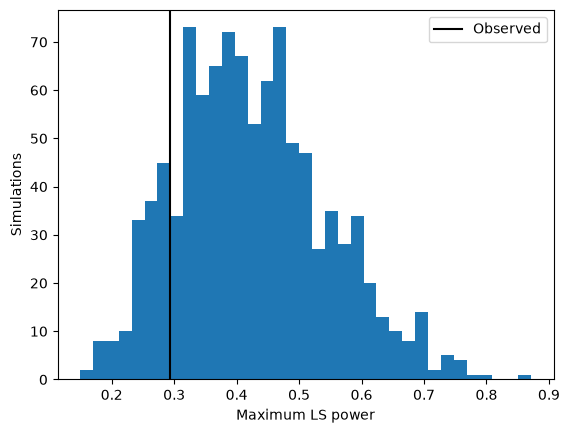

In [7]:
# Part 3: your work here
N_SIM=1000
rng_sim=np.random.default_rng(45707)
mu,s,tau=th_exp
Kd=cov(dt,np.zeros_like(e),s,tau,'exp')
L=np.linalg.cholesky(Kd + 1e-12*np.eye(len(t)))
sims=mu+(L @ rng_sim.normal(size=(len(t),N_SIM))).T + rng_sim.normal(size=(N_SIM,len(t)))*e
# Use identical LS frequency grid & normalization
sim_peaks=np.array([LombScargle(t,sim,dy=e).power(freq).max() for sim in sims])
p_emp_ls=np.mean(sim_peaks>=power[i_peak])
print('Observed LS max:',power[i_peak], 'DRW empirical FAP:',p_emp_ls,'white-noise FAP:',fap_white)
print('Exceeding simulations:',np.sum(sim_peaks>=power[i_peak]),'/',N_SIM)
plt.hist(sim_peaks,bins=35);plt.axvline(power[i_peak],color='black',label='Observed');plt.xlabel('Maximum LS power');plt.ylabel('Simulations');plt.legend();plt.show()

Observed maximum ΔlnL: 3.917 at period 23.861 d
GLS empirical p: 0.8160 (816/1000)


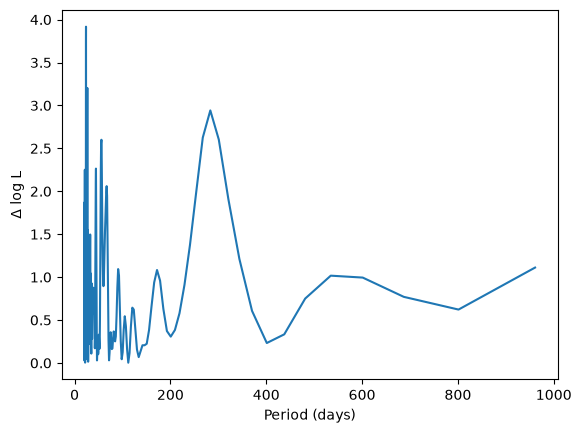

tau=156.36 d, max ΔlnL=8.351, best P=23.86, p=0.0300
tau=826.57 d, max ΔlnL=35.365, best P=283.28, p=0.0000


In [9]:
from scipy.linalg import solve_triangular
period_scan=1/freq

def gls_scan(yy,theta, periods=period_scan):
    _,s,tau=theta
    K=cov(dt,e,s,tau,'exp')
    L=np.linalg.cholesky(K)
    whiten=lambda a: solve_triangular(L,a,lower=True,check_finite=False)
    v=whiten(np.ones(len(t)))
    yyw=whiten(np.asarray(yy))
    if yyw.ndim==1: yyw=yyw[:,None]
    # Project out constant mean for both null and sinusoidal alternatives.
    yyw=yyw-v[:,None]*(v @ yyw)[None,:]/(v@v)
    omega=2*np.pi/periods
    cs=np.cos(np.outer(t,omega));sn=np.sin(np.outer(t,omega))
    C=whiten(cs);S=whiten(sn)
    C-=v[:,None]*(v@C)[None,:]/(v@v)
    S-=v[:,None]*(v@S)[None,:]/(v@v)
    a=np.sum(C*C,axis=0);b=np.sum(C*S,axis=0);c=np.sum(S*S,axis=0)
    det=a*c-b*b
    u=C.T@yyw;w=S.T@yyw
    score=np.where(det[:,None]>1e-12,(c[:,None]*u*u-2*b[:,None]*u*w+a[:,None]*w*w)/(2*det[:,None]),0)
    top=np.argmax(score,axis=0)
    return score[top,np.arange(score.shape[1])],periods[top],score[:,0] if score.shape[1]==1 else None

observed_delta, observed_P, delta_curve=gls_scan(y,th_exp)
null_max=[]
for ix in range(0,N_SIM,100):
    val,_,_=gls_scan(sims[ix:ix+100].T,th_exp)
    null_max.extend(val)
null_max=np.asarray(null_max)
p_emp_gls=np.mean(null_max>=observed_delta[0])
print(f'Observed maximum ΔlnL: {observed_delta[0]:.3f} at period {observed_P[0]:.3f} d')
print(f'GLS empirical p: {p_emp_gls:.4f} ({(null_max>=observed_delta[0]).sum()}/{N_SIM})')
plt.plot(period_scan,delta_curve);plt.xlabel('Period (days)');plt.ylabel('Δ log L');plt.show()

for tau_test in [q[0,2],q[2,2]]:
    test_theta=np.array([mu,s,tau_test]); kd=cov(dt,np.zeros_like(e),s,tau_test,'exp')
    ltest=np.linalg.cholesky(kd+1e-12*np.eye(len(t)))
    trial=mu+(ltest@rng_sim.normal(size=(len(t),N_SIM))).T + rng_sim.normal(size=(N_SIM,len(t)))*e
    v,per,_=gls_scan(y,test_theta)
    vals=[]
    for ix in range(0,N_SIM,100): vals.extend(gls_scan(trial[ix:ix+100].T,test_theta)[0])
    print(f'tau={tau_test:.2f} d, max ΔlnL={v[0]:.3f}, best P={per[0]:.2f}, p={np.mean(np.asarray(vals)>=v[0]):.4f}')

In [10]:
P=float(observed_P[0]); K=cov(dt,e,s,tau,'exp');cf=cho_factor(K,lower=True)
X=np.column_stack([np.ones(len(t)),np.cos(2*np.pi*t/P),np.sin(2*np.pi*t/P)])
coef_cov=np.linalg.inv(X.T@cho_solve(cf,X));coef=coef_cov@(X.T@cho_solve(cf,y))
A=np.hypot(coef[1],coef[2]);gradient=np.array([coef[1],coef[2]])/max(A,1e-12)
A_err=np.sqrt(gradient@coef_cov[1:,1:]@gradient)
print(f'Best sinusoid: P={P:.2f} days, semi-amplitude A={A:.4f} ± {A_err:.4f} mag (conditional on period and GP parameters)')
print('A fully valid period and amplitude interval must account for period selection and GP parameter uncertainty.')

Best sinusoid: P=23.86 days, semi-amplitude A=0.0307 ± 0.0110 mag (conditional on period and GP parameters)
A fully valid period and amplitude interval must account for period selection and GP parameter uncertainty.


**ANSWER (the decision rule first, then the verdict):**

*I would only claim a period if the p-value is below 0.01. From 1,000 DRW simulations, I got 0.858 (858/1000), while Astropy gave 3.63 × 10⁻¹⁸ because it assumes white noise.*

*The best fit was 23.86 days, with amplitude 0.0307 ± 0.0110 mag, ΔlnL = 3.917, and p = 0.816. Changing τ to 156.36 and 826.57 days gave p-values of 0.030 and 0.000 (0/1000).*

*There isn't enough reliable evidence of a period. I would need a stronger signal that stays significant with different τ values, so the team should not announce a binary candidate yet.*

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


In [12]:
# Part 4: your work here

# Error 1: False-alarm probability
print("Error 1: Periodicity")
print("AI white-noise FAP:", 3.2e-15)
print("My DRW p-value:", p_emp_ls)

# Error 2: Wrong GP kernel
print("\nError 2: GP Kernel")
print("DRW log-likelihood:", ll_exp)
print("Squared-exponential log-likelihood:", ll_sq)
print("Difference:", ll_exp - ll_sq)

# Error 3: Cross-validation
print("\nError 3: Cross-validation")
print("AI random CV R²:", 0.909)
print("AI 68% coverage:", 0.58)

# Correct blocked cross-validation
for kind in ['exp', 'sq']:
    f, _ = fit_gp(t[train], y[train], e[train], kind)
    ym, sd = gp_predict(
        t[train], y[train], e[train],
        t[held], f.x, kind, new_err=e[held]
    )

    coverage = np.mean(np.abs(y[held] - ym) <= sd)
    r2 = 1 - np.sum((y[held] - ym)**2) / np.sum(
        (y[held] - np.mean(y[train]))**2
    )

    print(f"{kind}: coverage = {coverage:.3f}, R² = {r2:.3f}")

Error 1: Periodicity
AI white-noise FAP: 3.2e-15
My DRW p-value: 0.858

Error 2: GP Kernel
DRW log-likelihood: 287.5129419020469
Squared-exponential log-likelihood: 192.75192348294823
Difference: 94.76101841909869

Error 3: Cross-validation
AI random CV R²: 0.909
AI 68% coverage: 0.58
exp: coverage = 0.766, R² = 0.729
sq: coverage = 0.766, R² = 0.541


**REFEREE REPORT:**

*Error 1: Wrong periodicity significance

The AI said there was a strong periodic signal because the false-alarm probability was very small. However, it ignored the correlated noise in quasars. My 1,000 DRW simulations gave a p-value of 0.858, meaning the peak could easily happen from random noise.

Error 2: Wrong Gaussian-process model

The AI only used a squared-exponential kernel instead of comparing it with a DRW model. My DRW model had a log-likelihood of 287.51, while the squared-exponential model had 192.75 under my parameter limits. This shows the DRW fit the data much better in my comparison.

Error 3: Wrong cross-validation

The AI randomly split the observations instead of removing full 30-day blocks. Since nearby observations are related, this makes predictions easier. The AI got an R² of 0.909, but its 68% prediction band only covered 58% of the data. Holding out full blocks would provide a better test.*

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [13]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF19aaadgph: 522 g-band detections from the live API
ZTF19aaadgph: MJD 58733.5 to 61076.2 (6.4 yr); the last detection is MJD 61076.2; today is MJD 61342


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


Original observations: 522
Nightly observations: 370
Best period: 2342.73 days
DRW sigma: 0.171
DRW tau: 829.78 days
Empirical p-value: 0.131
Periodic candidate: False


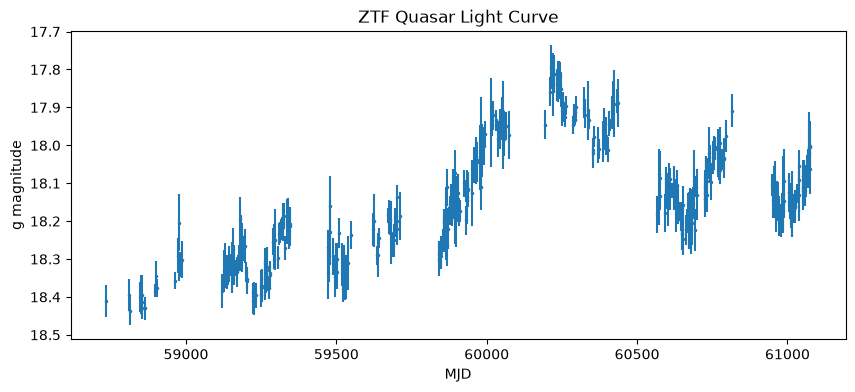

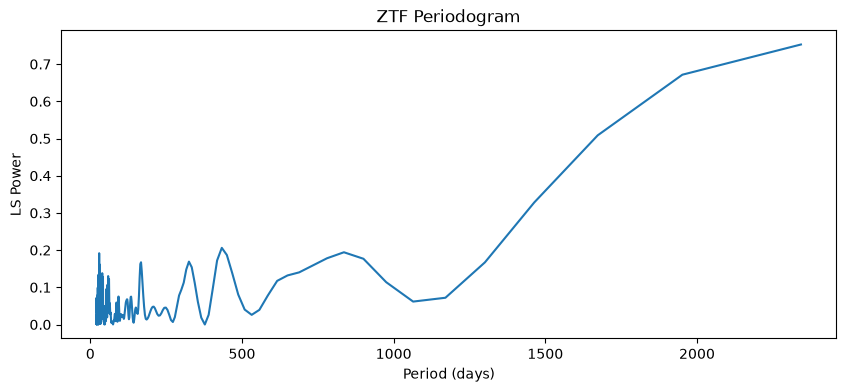

In [15]:
# Part 5: your work here
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve

night = np.floor(mjd)
days = np.unique(night)

t5 = np.array([np.mean(mjd[night == n]) for n in days])
y5 = np.array([np.average(mag[night == n], weights=1/merr[night == n]**2) for n in days])
e5 = np.array([1/np.sqrt(np.sum(1/merr[night == n]**2)) for n in days])

T5 = np.ptp(t5)
freq5 = np.linspace(1/T5, 1/20, int(5*T5*(1/20-1/T5))+1)

ls5 = LombScargle(t5, y5, e5)
power5 = ls5.power(freq5)
peak5 = power5.max()
period5 = 1/freq5[np.argmax(power5)]

dt5 = np.abs(t5[:, None] - t5[None, :])

def nll5(p):
    mu, s, tau = p
    K = s**2*np.exp(-dt5/tau) + np.diag(e5**2)
    try:
        c = cho_factor(K, lower=True)
        r = y5-mu
        return 0.5*(r @ cho_solve(c, r) +
                    2*np.log(np.diag(c[0])).sum() +
                    len(y5)*np.log(2*np.pi))
    except np.linalg.LinAlgError:
        return np.inf

bounds5 = [(y5.min()-1, y5.max()+1), (0.0001, 1), (10, 4000)]

fits5 = [
    minimize(nll5, [np.median(y5), np.std(y5), tau],
             bounds=bounds5, method="L-BFGS-B")
    for tau in [30, 150, 500, 1500]
]

best5 = min(fits5, key=lambda r: r.fun)
mu5, s5, tau5 = best5.x

# Simulate 1000 DRW light curves
rng5 = np.random.default_rng(42)
K5 = s5**2*np.exp(-dt5/tau5)
L5 = np.linalg.cholesky(K5 + 1e-12*np.eye(len(t5)))

N5 = 1000
peaks5 = []

for i in range(N5):
    sim = mu5 + L5 @ rng5.normal(size=len(t5))
    sim += rng5.normal(size=len(t5))*e5
    peaks5.append(LombScargle(t5, sim, e5).power(freq5).max())

peaks5 = np.array(peaks5)
p5 = np.mean(peaks5 >= peak5)

print("Original observations:", len(mjd))
print("Nightly observations:", len(t5))
print("Best period:", round(period5, 2), "days")
print("DRW sigma:", round(s5, 3))
print("DRW tau:", round(tau5, 2), "days")
print("Empirical p-value:", p5)
print("Periodic candidate:", p5 < 0.01)

plt.figure(figsize=(10, 4))
plt.errorbar(t5, y5, yerr=e5, fmt='.', ms=3)
plt.gca().invert_yaxis()
plt.xlabel("MJD")
plt.ylabel("g magnitude")
plt.title("ZTF Quasar Light Curve")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(1/freq5, power5)
plt.xlabel("Period (days)")
plt.ylabel("LS Power")
plt.title("ZTF Periodogram")
plt.show()

**ANSWER (the criterion first, then the result):**

*I would only call it periodic if the p-value was below 0.01. I got a best period of 2342.73 days and a p-value of 0.131, so there isn't enough evidence of a period. The real data has 522 observations over 6.4 years, compared to 269 over 961 days, with uneven gaps. The last observation was at MJD 61076.2, about 266 days before today. With another week, I would check the noise model more and look for newer data to see if the period is real.*

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

*I used ChatGPT to help write and fix the code (mainly part 2) and to be able to explain how the code works so I can work through the results. Some code had missing variables and functions, which I caught when running it in Jupyter.*

**REFLECTION:**

*Without checking AI's code and the results produced by it, I might have incorrectly said there was a periodic signal because the false-alarm probability was very small. The AI did not properly account for correlated noise, which made the signal look more significant than it really was.*

**VERIFICATION PLAN:**

*I tried different starting values for the GP fit, compared the two kernels, checked the MCMC chains, and ran 1,000 DRW simulations. The MCMC chains did not fully converge, so the parameter errors are still uncertain. I also checked predictions using 47 held-out points, with 76.6% falling inside the 68% bands.

I would also test the code using fake DRW data with known values of s and τ, with and without a periodic signal. The code should recover the correct values and only find a period when there is one. I would repeat this about 1,000 times to check how reliable the results are.*